# 6. Shape

Run the cells from top to bottom. Select the `mano` kernel. The working directory may be `MANO` or `MANO/tutorial`.

`betas` changes the hand's body shape. If the pose stays flat, changing `betas` still gives an open hand. The hand is larger, smaller, or differently proportioned.

## The formula

```text
v_shaped = v_template + Σ_k  beta_k * shapedirs[:, :, k]
J        = J_regressor @ v_shaped
```

`shapedirs` has shape `(778, 3, 10)`. Each slice along the last axis is a 778×3 displacement field. `beta_k` is the coefficient of slice k. When every `beta` is 0, the sum is 0 and `v_shaped` is the template.

The official pickle stores 20 shape components. The released model keeps the first 10 by index, so the array you read has shape `(778, 3, 10)`. `forward` uses only as many of the coefficients you pass as that last axis allows.

`J_regressor` is `(16, 778)`. Each row picks some vertices, weights them, and sums them into one joint. In this `MANO_RIGHT.pkl` every row is nonnegative and sums to 1, so each rest joint is a weighted average of vertices. It lands in the region those vertices span, usually inside the skin, not exactly on one vertex.

Pose blend shapes are not part of `J`. Rest joints see shape only.

## The whole calculation on the toy finger

`toy_mano.py` has 5 vertices. Vertices 0, 1, 2, and 3 sit on the wrist, MCP, PIP, and DIP. Their rest y coordinates are 0, 1, 2, and 3. Vertex 4 is skin beside the PIP.

The single shape component moves two numbers: the PIP vertex's y grows by `0.2 * beta`, and the DIP vertex's y grows by `0.4 * beta`. Joint i is defined as vertex i.

At `beta = 1`, the DIP joint should move from `(0, 3, 0)` to `(0, 3.4, 0)`.


In [3]:
import sys
from pathlib import Path

import numpy as np

MANO = Path.cwd().resolve()
if not (MANO / "mano_skeleton.py").exists():
    MANO = MANO.parent
if str(MANO) not in sys.path:
    sys.path.insert(0, str(MANO))

import toy_mano as toy

mean = toy.forward(betas=[0.0])
long = toy.forward(betas=[1.0])
print("DIP rest joint, beta 0:", mean["joints_rest"][3])
print("DIP rest joint, beta 1:", long["joints_rest"][3])
delta = long["joints_rest"][3, 1] - mean["joints_rest"][3, 1]
print("DIP moved along y by", delta)
assert np.isclose(delta, 0.4)
assert np.allclose(mean["joints_rest"][0], 0.0)


DIP rest joint, beta 0: [0. 3. 0.]
DIP rest joint, beta 1: [0.  3.4 0. ]
DIP moved along y by 0.3999999999999999


## On the official right hand

`beta[0]` is the component with the largest variation. It mostly changes the overall scale of the hand. The pose stays on the flat template. The next cell prints the wrist-to-middle-fingertip length and draws the hand at `beta[0]` equal to -2, 0, and +2. All three hands are open. A fist is a change to `hand_pose`.


beta[0] = -2    wrist to middle tip 191.5 mm
beta[0] = +0    wrist to middle tip 175.3 mm
beta[0] = +2    wrist to middle tip 159.0 mm


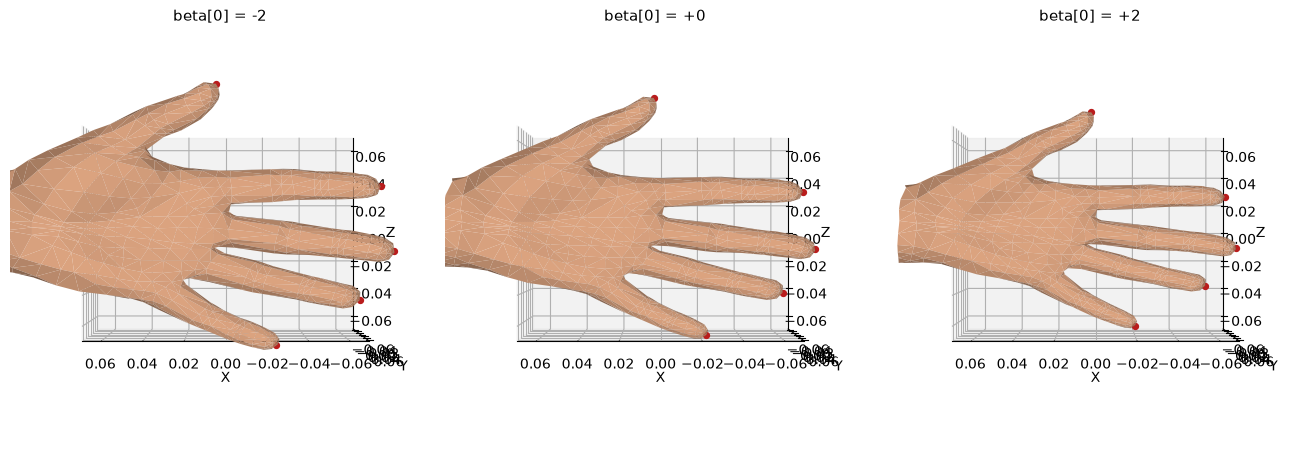

In [4]:
%matplotlib inline
from official_mano import require_model

model = require_model()
def show_hands(panels, faces, titles):
    """View the mesh from the palm side (-Y). Red points are the five fingertips."""
    import matplotlib.pyplot as plt
    from mpl_toolkits.mplot3d.art3d import Poly3DCollection

    palm = np.array([0.0, -1.0, 0.0])
    cloud = np.vstack([item["vertices"] for item in panels])
    fig = plt.figure(figsize=(4.4 * len(panels), 4.6))
    for index, (title, result) in enumerate(zip(titles, panels), start=1):
        axis = fig.add_subplot(1, len(panels), index, projection="3d")
        triangles = result["vertices"][faces]
        normals = np.cross(triangles[:, 1] - triangles[:, 0], triangles[:, 2] - triangles[:, 0])
        normals /= np.maximum(np.linalg.norm(normals, axis=1, keepdims=True), 1e-12)
        facing = normals @ palm > 0.0
        shade = 0.55 + 0.45 * np.abs(normals[facing] @ palm)
        color = np.zeros((int(facing.sum()), 4))
        color[:, 0] = 0.86 * shade
        color[:, 1] = 0.64 * shade
        color[:, 2] = 0.50 * shade
        color[:, 3] = 1.0
        axis.add_collection3d(Poly3DCollection(triangles[facing], facecolors=color, linewidths=0))
        tips = np.stack([result["tips"][name] for name in ("thumb", "index", "middle", "ring", "pinky")])
        axis.scatter(tips[:, 0], tips[:, 1], tips[:, 2], s=18, c="#b91c1c", depthshade=False)
        axis.set_title(title, fontsize=11)
        axis.view_init(elev=0, azim=90)
        axis.set_xlabel("X")
        axis.set_ylabel("Y")
        axis.set_zlabel("Z")
        center = cloud.mean(axis=0)
        radius = 0.55 * np.max(np.linalg.norm(cloud - center, axis=1))
        axis.set_xlim(center[0] - radius, center[0] + radius)
        axis.set_ylim(center[1] - radius, center[1] + radius)
        axis.set_zlim(center[2] - radius, center[2] + radius)
    fig.tight_layout()
    plt.show()

panels = []
titles = []
for beta0 in (-2.0, 0.0, 2.0):
    betas = np.zeros(10)
    betas[0] = beta0
    out = model.forward(betas=betas, flat_hand=True)
    length = np.linalg.norm(out["tips"]["middle"] - out["joints"][0]) * 1000
    print(f"beta[0] = {beta0:+.0f}    wrist to middle tip {length:.1f} mm")
    panels.append(out)
    titles.append(f"beta[0] = {beta0:+.0f}")

show_hands(panels, model.faces, titles)


The three lengths should be about 191.5 mm, 175.3 mm, and 159.0 mm.

## Check

`betas` moves the rest joints, because `J = J_regressor @ v_shaped`. A fist is a change to `hand_pose`.

The next chapter looks at the extra displacement that appears on the skin after a finger bends.
